# PCA, K-means and Bubble Plot

Workflow for morphological profiling of G0-arrested, proliferative and other conditions.

The notebook:
- standardizes the selected morphological features;
- performs PCA;
- determines the number of K-means clusters using silhouette score;
- performs K-means in the retained PCA space;
- visualizes treatment distributions in PCA space;
- generates a bubble plot showing the distribution of each condition across clusters;
- exports all figures and tables to the **same folder in which the notebook is being run**.


In [1]:
# ============================================================
# 1. Imports, paths and publication style
# ============================================================
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D

RANDOM_STATE = 42

# The Jupyter working directory is normally the notebook directory.
# All figures/tables are saved here.
OUTPUT_DIR = Path.cwd()
print(f"Output directory: {OUTPUT_DIR.resolve()}")

# ------------------------------------------------------------
# Biological colour convention
# ------------------------------------------------------------
G0_COLOR = "#2E8B57"        # green
PROLIF_COLOR = "#7B3FB3"    # purple

OTHER_COLORS = [
    "#5F7FA3",  # muted blue
    "#C18C5D",  # muted ochre
    "#A56B8A",  # dusty mauve
    "#6F9B8F",  # muted teal
    "#9B8F6F",  # khaki
    "#7E78A8",  # muted indigo
    "#B07A70",  # terracotta
    "#7698A5",  # blue-grey
    "#8F9A6D",  # olive
    "#A07C98",  # mauve-grey
    "#778899",  # slate
    "#B18A5B",  # sand-brown
]

# Cluster colours are deliberately distinct from the biological state palette.
# Cluster IDs are unsupervised and should not be interpreted as cell states.
CLUSTER_COLORS = [
    "#4C78A8",
    "#F2A65A",
    "#8B8B8B",
    "#B279A2",
    "#72A98F",
    "#E17C7C",
    "#8C83C6",
    "#B7A36A",
]

# ------------------------------------------------------------
# Publication typography
# ------------------------------------------------------------
TITLE_SIZE = 20
AXIS_SIZE = 17
TICK_SIZE = 14
LEGEND_SIZE = 13
ANNOT_SIZE = 12

sns.set_theme(context="paper", style="ticks", font_scale=1.0)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 400,
    "font.size": 14,
    "axes.titlesize": TITLE_SIZE,
    "axes.titleweight": "bold",
    "axes.labelsize": AXIS_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
    "legend.title_fontsize": LEGEND_SIZE,
    "axes.linewidth": 1.2,
    "xtick.major.width": 1.1,
    "ytick.major.width": 1.1,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "savefig.facecolor": "white",
    "savefig.bbox": "tight",
})

def clean_axes(ax):
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    sns.despine(ax=ax)
    return ax

def get_condition_palette(labels):
    labels = [str(x) for x in labels]
    palette = {}
    other_index = 0

    for label in labels:
        lower = label.lower()

        if "g0" in lower or (
            "dormant" in lower
            and "non-dormant" not in lower
            and "nondorm" not in lower
        ):
            palette[label] = G0_COLOR

        elif (
            "proliferative" in lower
            or "non-dormant" in lower
            or "nondorm" in lower
        ):
            palette[label] = PROLIF_COLOR

        else:
            palette[label] = OTHER_COLORS[
                other_index % len(OTHER_COLORS)
            ]
            other_index += 1

    return palette

Output directory: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis


## 2. Load data

Edit only `DATA_PATH` if the normalized CSV is stored somewhere else.

In [2]:
# ============================================================
# 2. Load normalized data
# ============================================================

DATA_PATH = Path(
    "/Users/thaismlacerda/Library/CloudStorage/"
    "GoogleDrive-thaismllacerda@gmail.com/Meu Drive/"
    "Doutorado Thais/Github_Analysis/Dormancy_Recovery/"
    "Normalized/Recovery_NonDormant_Normalized.csv"
)

if not DATA_PATH.exists():
    # Useful fallback when the CSV is placed beside the notebook.
    local_candidates = list(
        OUTPUT_DIR.glob("*Recovery*NonDormant*Normalized*.csv")
    )

    if len(local_candidates) == 1:
        DATA_PATH = local_candidates[0]
        print(f"Using local CSV: {DATA_PATH}")

    elif len(local_candidates) > 1:
        raise FileNotFoundError(
            "Several possible normalized CSV files were found in the "
            "notebook directory. Set DATA_PATH explicitly."
        )

    else:
        raise FileNotFoundError(
            f"Normalized CSV was not found at:\n{DATA_PATH}\n\n"
            "Set DATA_PATH to the correct file location."
        )

df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Rows: 52
Columns: 301


,Unnamed: 0,Metadata_Plate,Metadata_Well,Metadata_plate_map_name,Metadata_cell,Metadata_condition,Metadata_concentration_uM,Metadata_control_type,Nuclei_cell_count,Nuclei_AreaShape_CentralMoment_0_1,...,Cells_RadialDistribution_FracAtD_AOGFP_3of4,Cells_RadialDistribution_MeanFrac_AOGFP_3of4,Cells_RadialDistribution_MeanFrac_AOPI_3of4,Cells_RadialDistribution_RadialCV_AOGFP_1of4,Cells_RadialDistribution_RadialCV_AOPI_1of4,Cells_RadialDistribution_RadialCV_AOPI_2of4,Cells_RadialDistribution_RadialCV_AOPI_3of4,Cells_RadialDistribution_RadialCV_AOPI_4of4,Cells_Texture_DifferenceEntropy_AOPI_10_00_256,Cells_Texture_InfoMeas1_AOGFP_5_00_256
0,260,240806_171324_Plate_1_,B7,layout_l3_day2,MCF7,Non-dormant,0.0,trt,3.545123,-0.805885,...,-3.599492,-2.036982,-1.636874,-4.500760,1.187802,-0.715352,0.179855,-0.200429,-9.507381,3.624114
1,270,240806_171324_Plate_1_,C7,layout_l3_day2,MCF7,Non-dormant,0.0,trt,1.947929,0.035038,...,-6.411229,-2.595423,-1.382452,-5.026085,0.403936,-0.723144,-1.309331,-2.878341,-31.428329,-0.258192
2,280,240806_171324_Plate_1_,D7,layout_l3_day2,MCF7,Non-dormant,0.0,trt,4.451639,-1.016116,...,-5.956163,-2.977383,-2.756912,-7.229588,-3.280073,-2.996894,-3.403975,-3.684385,-33.325681,0.916055
3,290,240806_171324_Plate_1_,E7,layout_l3_day2,MCF7,Non-dormant,0.0,trt,3.232160,0.437981,...,-6.590615,-3.269344,-3.462117,-7.926233,-5.208445,-4.224854,-4.464659,-4.767788,-38.550089,0.897166
4,0,250224_132655_Plate_1_,B2,layout_day1,MCF7,Dormant,NaN,negcon,-0.182913,0.373564,...,0.066481,-0.630746,-0.344810,2.051680,-0.117167,1.234155,0.292903,0.537095,-0.303277,-4.330535


## 3. Preprocessing

Metadata are preserved separately from the morphological feature matrix. Infinite values are converted to missing values and imputed using the median of each feature. Constant features are removed before scaling.

In [3]:
# ============================================================
# 3. Preprocessing
# ============================================================

CONDITION_COL = "Metadata_condition"

if CONDITION_COL not in df.columns:
    raise KeyError(
        f"Required condition column '{CONDITION_COL}' was not found."
    )

analysis_df = df.copy()

# Standardize condition naming.
analysis_df[CONDITION_COL] = (
    analysis_df[CONDITION_COL]
    .replace({
        "Dormant": "G0-arrested",
        "Non-dormant": "Proliferative",
        "Non-Dormant": "Proliferative",
    })
    .astype(str)
)

# Remove variables that should not enter the morphology space.
columns_to_drop = [
    col
    for col in [
        "Nuclei_cell_count",
    ]
    if col in analysis_df.columns
]

analysis_df = analysis_df.drop(
    columns=columns_to_drop,
    errors="ignore",
)

analysis_df = analysis_df.loc[
    :,
    ~analysis_df.columns.str.contains(
        "ImageNumber",
        case=False,
        regex=False,
    ),
].copy()

# Metadata columns are excluded from PCA/K-means.
metadata_mask = analysis_df.columns.str.contains(
    r"^(Metadata_|Unnamed)",
    regex=True,
)

feature_cols = analysis_df.columns[
    ~metadata_mask
].tolist()

X = analysis_df[feature_cols].copy()
y = analysis_df[CONDITION_COL].copy()

# Numeric conversion + robust missing-value handling.
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Remove all-NA features.
all_na_features = X.columns[X.isna().all()].tolist()
if all_na_features:
    X = X.drop(columns=all_na_features)

# Median imputation.
X = X.fillna(X.median(numeric_only=True))

# Remove zero-variance features.
feature_std = X.std(axis=0, ddof=0)
constant_features = feature_std[
    (~np.isfinite(feature_std))
    | (feature_std <= 1e-12)
].index.tolist()

if constant_features:
    X = X.drop(columns=constant_features)

feature_cols = X.columns.tolist()

print(f"Conditions: {y.nunique()}")
print(f"Features retained: {len(feature_cols)}")
print(f"All-NA features removed: {len(all_na_features)}")
print(f"Constant features removed: {len(constant_features)}")

condition_counts = (
    y.value_counts()
    .rename_axis("Condition")
    .reset_index(name="Profiles")
)
display(condition_counts)

Conditions: 9
Features retained: 291
All-NA features removed: 0
Constant features removed: 0


/var/folders/xc/x2b6cmd93rbcjw3gmr43k0kc0000gn/T/ipykernel_15460/381477266.py:49: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  metadata_mask = analysis_df.columns.str.contains(


,Condition,Profiles
0,G0-arrested,6
1,Day1,6
2,Day2,6
3,Day3,6
4,Day4,6
5,Day5,6
6,Day6,6
7,Day7,6
8,Proliferative,4


In [4]:
# ============================================================
# 4. Feature scaling
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(f"Scaled matrix: {X_scaled.shape[0]} profiles × {X_scaled.shape[1]} features")

Scaled matrix: 52 profiles × 291 features


## 4. Robust multivariate outlier detection

Before the definitive PCA and K-means analyses, profiles are screened for multivariate outliers **within each biological condition**. This prevents legitimate differences between G0-arrested, proliferative and drug-treated conditions from being mistaken for technical outliers.

A temporary PCA is calculated from the standardized feature matrix. For each condition, the Euclidean distance of each profile from the robust median centre is calculated in the first principal components, and a MAD-based robust z-score is obtained. Profiles with a robust z-score above the predefined threshold are removed from subsequent analyses.

The removed profiles are listed and exported for transparency.

Candidate outliers: 4 / 52 profiles (threshold > 3.5 robust z)


,Metadata_condition,Profiles,Candidate_outliers,Median_robust_distance,Candidate_outliers_percent
0,Day1,6,0,6.286229,0.000000
1,Day2,6,0,6.652440,0.000000
2,Day3,6,1,6.481568,16.666667
3,Day4,6,1,4.661073,16.666667
4,Day5,6,1,2.822233,16.666667
5,Day6,6,0,4.385812,0.000000
6,Day7,6,0,6.499315,0.000000
7,G0-arrested,6,0,4.497311,0.000000
8,Proliferative,4,1,4.347774,25.000000


,QC_PC1,QC_PC2,QC_PC3,QC_PC4,QC_PC5,QC_PC6,QC_PC7,QC_PC8,QC_PC9,QC_PC10,Metadata_condition,Metadata_Plate,Metadata_Well,Robust_distance,Outlier_robust_z,Candidate_outlier
33,3.670410,-32.745221,2.372062,-20.686484,5.203385,-2.312395,-0.877436,-2.639011,1.023228,-0.021611,Day4,250228_130850_Plate_1_,G6,38.839311,28.958994,True
23,12.402134,-13.115707,-27.805469,14.860594,-7.374769,-5.601067,5.913803,-1.504858,0.379560,-0.573674,Day3,250227_124137_Plate_1_,C5,36.966422,15.877292,True
39,-6.756084,-1.215195,3.039812,3.349921,10.233307,1.969534,9.211758,1.526953,-1.821549,-5.418104,Day5,250301_122152_Plate_1_,G8,10.806291,5.606434,True
0,-0.590867,-4.209672,11.017938,8.163605,-5.527115,-2.177228,4.743783,0.546208,-3.662965,2.452857,Proliferative,240806_171324_Plate_1_,B7,11.898504,3.757794,True


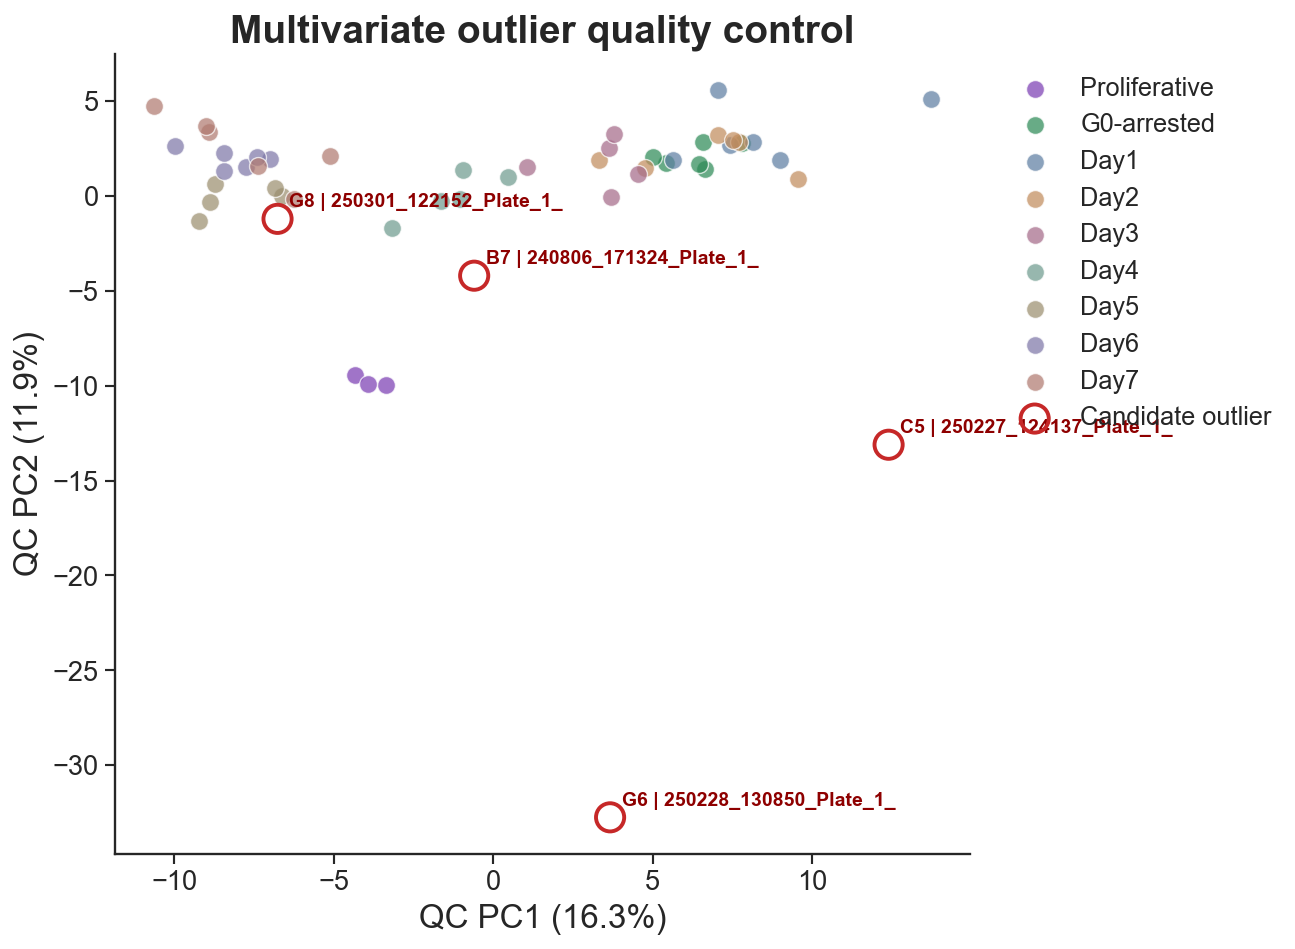

Removed 4 candidate outlier profiles. Remaining profiles: 48
QC tables and figure saved in: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis


In [5]:
# ============================================================
# 4A. Robust multivariate outlier detection before PCA
# ============================================================

REMOVE_OUTLIERS = True

# Conservative default. Lower to 3.0 only if you intentionally want
# a somewhat more permissive outlier filter.
OUTLIER_ROBUST_Z_THRESHOLD = 3.5

# Temporary QC PCA: use enough PCs to capture broad multivariate structure
# without relying only on PC1/PC2.
N_QC_PCS = min(
    10,
    X_scaled.shape[1],
    X_scaled.shape[0] - 1,
)

if N_QC_PCS < 2:
    raise ValueError(
        "Not enough observations/features for multivariate outlier detection."
    )

qc_pca = PCA(
    n_components=N_QC_PCS,
    random_state=RANDOM_STATE,
)

X_qc_pca = qc_pca.fit_transform(
    X_scaled
)

qc_columns = [
    f"QC_PC{i+1}"
    for i in range(N_QC_PCS)
]

outlier_qc_df = pd.DataFrame(
    X_qc_pca,
    columns=qc_columns,
)

outlier_qc_df[CONDITION_COL] = (
    y.reset_index(drop=True)
)

# Preserve useful metadata when available.
metadata_candidates = [
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_compound",
    "Metadata_condition",
    "Replicate_ID",
]

for metadata_col in metadata_candidates:
    if (
        metadata_col in analysis_df.columns
        and metadata_col not in outlier_qc_df.columns
    ):
        outlier_qc_df[metadata_col] = (
            analysis_df[metadata_col]
            .reset_index(drop=True)
        )

outlier_qc_df["Robust_distance"] = np.nan
outlier_qc_df["Outlier_robust_z"] = np.nan

# ------------------------------------------------------------
# Distance from robust centre WITHIN each biological condition
# ------------------------------------------------------------
for condition, subset in outlier_qc_df.groupby(
    CONDITION_COL,
    observed=True,
):
    idx = subset.index

    coords = subset[
        qc_columns
    ].to_numpy(dtype=float)

    robust_center = np.median(
        coords,
        axis=0,
    )

    distances = np.linalg.norm(
        coords - robust_center,
        axis=1,
    )

    distance_median = np.median(
        distances
    )

    distance_mad = np.median(
        np.abs(
            distances - distance_median
        )
    )

    if (
        not np.isfinite(distance_mad)
        or distance_mad <= 1e-12
    ):
        robust_z = np.zeros_like(
            distances,
            dtype=float,
        )
    else:
        robust_z = (
            0.6745
            * (
                distances
                - distance_median
            )
            / distance_mad
        )

    outlier_qc_df.loc[
        idx,
        "Robust_distance"
    ] = distances

    outlier_qc_df.loc[
        idx,
        "Outlier_robust_z"
    ] = robust_z

outlier_qc_df["Candidate_outlier"] = (
    outlier_qc_df[
        "Outlier_robust_z"
    ]
    > OUTLIER_ROBUST_Z_THRESHOLD
)

candidate_outliers = (
    outlier_qc_df.loc[
        outlier_qc_df[
            "Candidate_outlier"
        ]
    ]
    .sort_values(
        "Outlier_robust_z",
        ascending=False,
    )
    .copy()
)

outlier_summary = (
    outlier_qc_df
    .groupby(
        CONDITION_COL,
        observed=True,
    )
    .agg(
        Profiles=(
            "Candidate_outlier",
            "size",
        ),
        Candidate_outliers=(
            "Candidate_outlier",
            "sum",
        ),
        Median_robust_distance=(
            "Robust_distance",
            "median",
        ),
    )
    .reset_index()
)

outlier_summary[
    "Candidate_outliers_percent"
] = (
    100
    * outlier_summary[
        "Candidate_outliers"
    ]
    / outlier_summary[
        "Profiles"
    ]
)

print(
    f"Candidate outliers: {len(candidate_outliers)} / "
    f"{len(outlier_qc_df)} profiles "
    f"(threshold > {OUTLIER_ROBUST_Z_THRESHOLD:.1f} robust z)"
)

display(outlier_summary)

if not candidate_outliers.empty:
    display(candidate_outliers)
else:
    print("No candidate outliers were detected.")

# ------------------------------------------------------------
# QC plot
# ------------------------------------------------------------
qc_plot_df = outlier_qc_df.copy()

fig, ax = plt.subplots(
    figsize=(9.5, 7.0)
)

retained_qc = qc_plot_df.loc[
    ~qc_plot_df[
        "Candidate_outlier"
    ]
]

outlier_qc = qc_plot_df.loc[
    qc_plot_df[
        "Candidate_outlier"
    ]
]

# Retained profiles shown by biological condition.
qc_condition_order = (
    retained_qc[
        CONDITION_COL
    ]
    .drop_duplicates()
    .astype(str)
    .tolist()
)

qc_palette = get_condition_palette(
    qc_condition_order
)

for condition in qc_condition_order:
    subset = retained_qc.loc[
        retained_qc[
            CONDITION_COL
        ].astype(str) == condition
    ]

    ax.scatter(
        subset["QC_PC1"],
        subset["QC_PC2"],
        s=85,
        alpha=0.72,
        color=qc_palette[condition],
        edgecolor="white",
        linewidth=0.7,
        label=condition,
    )

# Outliers deliberately shown in black/red outline so they cannot
# be confused with a biological condition.
if not outlier_qc.empty:
    ax.scatter(
        outlier_qc["QC_PC1"],
        outlier_qc["QC_PC2"],
        s=210,
        facecolor="none",
        edgecolor="#C62828",
        linewidth=2.0,
        marker="o",
        label="Candidate outlier",
        zorder=10,
    )

    for idx, row in outlier_qc.iterrows():
        annotation = []

        if "Metadata_Well" in row.index:
            annotation.append(
                str(row["Metadata_Well"])
            )

        if "Metadata_Plate" in row.index:
            annotation.append(
                str(row["Metadata_Plate"])
            )

        if not annotation:
            annotation.append(
                f"row {idx}"
            )

        ax.annotate(
            " | ".join(annotation),
            (
                row["QC_PC1"],
                row["QC_PC2"],
            ),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=10,
            color="#8E0000",
            fontweight="bold",
        )

ax.set_xlabel(
    f"QC PC1 ({qc_pca.explained_variance_ratio_[0]*100:.1f}%)"
)

ax.set_ylabel(
    f"QC PC2 ({qc_pca.explained_variance_ratio_[1]*100:.1f}%)"
)

ax.set_title(
    "Multivariate outlier quality control"
)

ax.legend(
    title="",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

clean_axes(ax)
plt.tight_layout()

outlier_qc_path = (
    OUTPUT_DIR
    / "QC_multivariate_outliers.png"
)

plt.savefig(
    outlier_qc_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

# ------------------------------------------------------------
# Apply exclusion BEFORE definitive PCA/K-means
# ------------------------------------------------------------
retained_mask = (
    ~outlier_qc_df[
        "Candidate_outlier"
    ].to_numpy()
)

if REMOVE_OUTLIERS:
    X = X.loc[
        retained_mask
    ].reset_index(drop=True)

    y = y.loc[
        retained_mask
    ].reset_index(drop=True)

    analysis_df = (
        analysis_df.loc[
            retained_mask
        ]
        .reset_index(drop=True)
    )

    # Re-fit scaling after removing candidate outliers.
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(
        X
    )

    print(
        f"Removed {int((~retained_mask).sum())} candidate outlier profiles. "
        f"Remaining profiles: {len(X):,}"
    )

else:
    print(
        "Candidate outliers were flagged but not removed "
        "(REMOVE_OUTLIERS = False)."
    )

# Export QC tables for auditability.
outlier_qc_df.to_csv(
    OUTPUT_DIR
    / "QC_all_profiles_outlier_metrics.csv",
    index=False,
)

candidate_outliers.to_csv(
    OUTPUT_DIR
    / "QC_removed_candidate_outliers.csv",
    index=False,
)

outlier_summary.to_csv(
    OUTPUT_DIR
    / "QC_outlier_summary_by_condition.csv",
    index=False,
)

print(
    f"QC tables and figure saved in: {OUTPUT_DIR.resolve()}"
)

## 5. Principal Component Analysis

PCA is used as an **unsupervised** representation of the dominant sources of morphological variance. K-means is subsequently performed in a retained PCA space rather than directly on only PC1/PC2.

In [6]:
# ============================================================
# 5. Definitive PCA after QC
# ============================================================

max_components = min(
    X_scaled.shape[0] - 1,
    X_scaled.shape[1],
)

pca = PCA(
    n_components=max_components,
    random_state=RANDOM_STATE,
)

X_pca = pca.fit_transform(X_scaled)

explained_variance = (
    pca.explained_variance_ratio_ * 100
)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
) * 100

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    CONDITION_COL: y.to_numpy(),
})

# Retain enough PCs for clustering to explain >=90% of variance,
# with at least 2 PCs.
N_PCS_CLUSTER = int(
    np.searchsorted(
        cumulative_variance,
        90.0,
    ) + 1
)

N_PCS_CLUSTER = max(
    2,
    min(N_PCS_CLUSTER, X_pca.shape[1]),
)

print(
    f"PC1: {explained_variance[0]:.1f}% variance | "
    f"PC2: {explained_variance[1]:.1f}% variance"
)
print(
    f"{N_PCS_CLUSTER} PCs retained for K-means "
    f"({cumulative_variance[N_PCS_CLUSTER - 1]:.1f}% cumulative variance)"
)

PC1: 19.2% variance | PC2: 11.6% variance
25 PCs retained for K-means (90.4% cumulative variance)


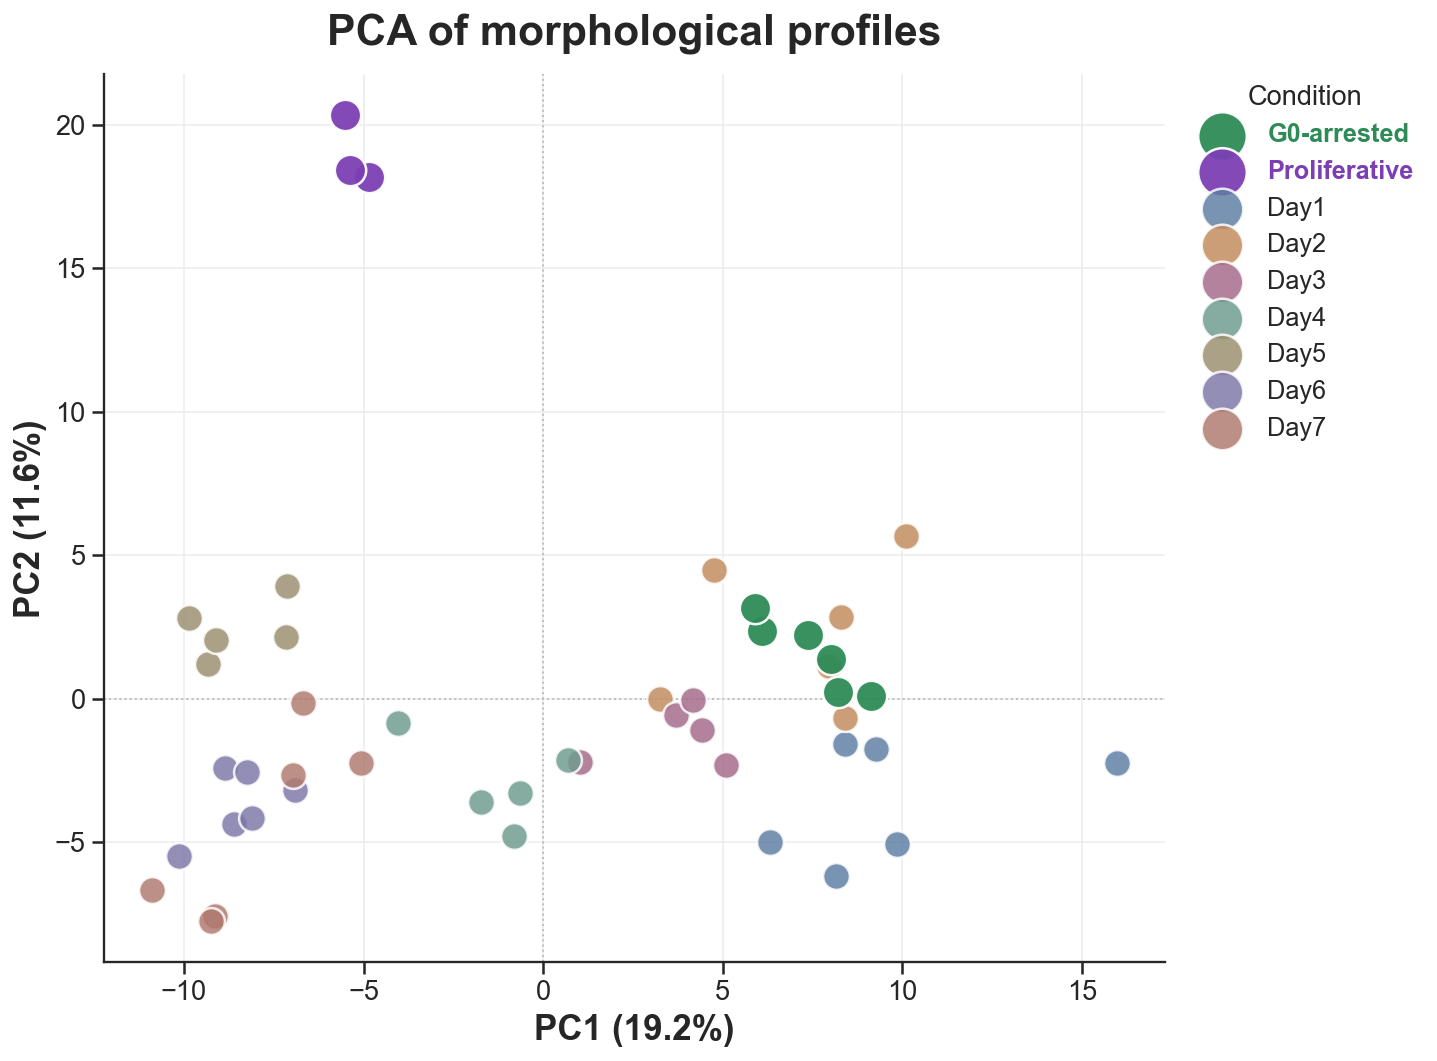

Saved: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis/PCA_morphological_profiles_publication.png


In [25]:
# ============================================================
# 6. PCA — publication-quality condition plot
# ============================================================

condition_order = y.drop_duplicates().astype(str).tolist()

# Put biological references first
condition_order = (
    [x for x in ["G0-arrested", "Proliferative"] if x in condition_order]
    + [
        x for x in condition_order
        if x not in {"G0-arrested", "Proliferative"}
    ]
)

condition_palette = get_condition_palette(
    condition_order
)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(10.5, 7.8)
)

# ------------------------------------------------------------
# Scatter plot
# ------------------------------------------------------------
for condition in condition_order:

    subset = pca_df.loc[
        pca_df[CONDITION_COL] == condition
    ]

    is_reference = condition in {
        "G0-arrested",
        "Proliferative",
    }

    marker_size = (
        260 if is_reference else 190
    )

    marker_alpha = (
        0.95 if is_reference else 0.84
    )

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=marker_size,
        alpha=marker_alpha,
        color=condition_palette[condition],
        edgecolor="white",
        linewidth=1.3,
        label=condition,
        zorder=3 if is_reference else 2,
    )

# ------------------------------------------------------------
# Zero lines
# ------------------------------------------------------------
ax.axhline(
    0,
    color="#BDBDBD",
    linewidth=1.0,
    linestyle=":",
    zorder=1,
)

ax.axvline(
    0,
    color="#BDBDBD",
    linewidth=1.0,
    linestyle=":",
    zorder=1,
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------
ax.set_xlabel(
    f"PC1 ({explained_variance[0]:.1f}%)",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    f"PC2 ({explained_variance[1]:.1f}%)",
    fontsize=18,
    fontweight="bold",
)

ax.set_title(
    "PCA of morphological profiles",
    fontsize=22,
    fontweight="bold",
    pad=15,
)

# ------------------------------------------------------------
# Ticks
# ------------------------------------------------------------
ax.tick_params(
    axis="both",
    labelsize=15,
    width=1.3,
    length=6,
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------
ax.grid(
    color="#ECECEC",
    linewidth=0.8,
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
legend = ax.legend(
    title="Condition",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    markerscale=1.55,
    fontsize=13,
    title_fontsize=14,
)

# Highlight reference conditions in legend
for txt in legend.get_texts():

    if txt.get_text() == "G0-arrested":
        txt.set_color(G0_COLOR)
        txt.set_fontweight("bold")

    elif txt.get_text() == "Proliferative":
        txt.set_color(PROLIF_COLOR)
        txt.set_fontweight("bold")

# ------------------------------------------------------------
# Clean axes
# ------------------------------------------------------------
clean_axes(ax)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
pca_path = OUTPUT_DIR / "PCA_morphological_profiles_publication.png"

plt.savefig(
    pca_path,
    dpi=500,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Saved: {pca_path}")

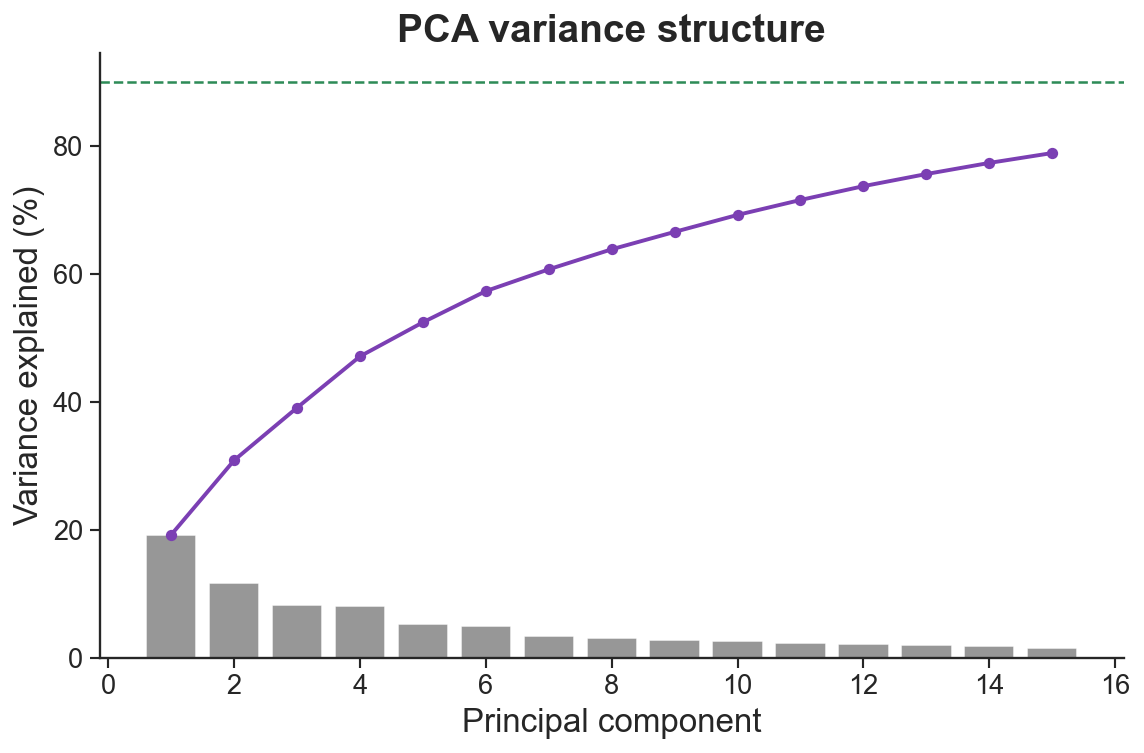

Saved: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis/PCA_variance_structure.png


In [8]:
# ============================================================
# 7. PCA variance diagnostic
# ============================================================

n_show = min(
    15,
    len(explained_variance),
)

fig, ax = plt.subplots(
    figsize=(8.4, 5.6)
)

ax.bar(
    np.arange(1, n_show + 1),
    explained_variance[:n_show],
    color="#8C8C8C",
    alpha=0.90,
)

ax.plot(
    np.arange(1, n_show + 1),
    cumulative_variance[:n_show],
    marker="o",
    linewidth=2.0,
    color=PROLIF_COLOR,
)

ax.axhline(
    90,
    color=G0_COLOR,
    linestyle="--",
    linewidth=1.3,
)

ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained (%)")
ax.set_title("PCA variance structure")

clean_axes(ax)
plt.tight_layout()

variance_path = OUTPUT_DIR / "PCA_variance_structure.png"

plt.savefig(
    variance_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Saved: {variance_path}")

## 6. K-means clustering

The number of clusters is selected from the retained PCA space using the silhouette score. Cluster IDs are mathematical labels only and are **not** assigned the green/purple biological-state colours.

In [9]:
# ============================================================
# 8. Select K using silhouette score
# ============================================================

X_cluster = X_pca[
    :,
    :N_PCS_CLUSTER,
]

max_k = min(
    8,
    len(X_cluster) - 1,
)

k_values = list(
    range(2, max_k + 1)
)

silhouette_rows = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=50,
    )

    labels = model.fit_predict(
        X_cluster
    )

    silhouette_rows.append({
        "k": k,
        "Silhouette score": silhouette_score(
            X_cluster,
            labels,
        ),
        "Inertia": model.inertia_,
    })

silhouette_table = pd.DataFrame(
    silhouette_rows
)

BEST_K = int(
    silhouette_table.loc[
        silhouette_table[
            "Silhouette score"
        ].idxmax(),
        "k",
    ]
)

print(f"Best k by silhouette: {BEST_K}")
display(silhouette_table)

Best k by silhouette: 3


,k,Silhouette score,Inertia
0,2,0.166752,10303.520053
1,3,0.204657,8903.266781
2,4,0.172270,7962.743229
3,5,0.171529,7229.196661
4,6,0.185433,6527.359882
5,7,0.190939,5965.416676
6,8,0.187320,5591.736311


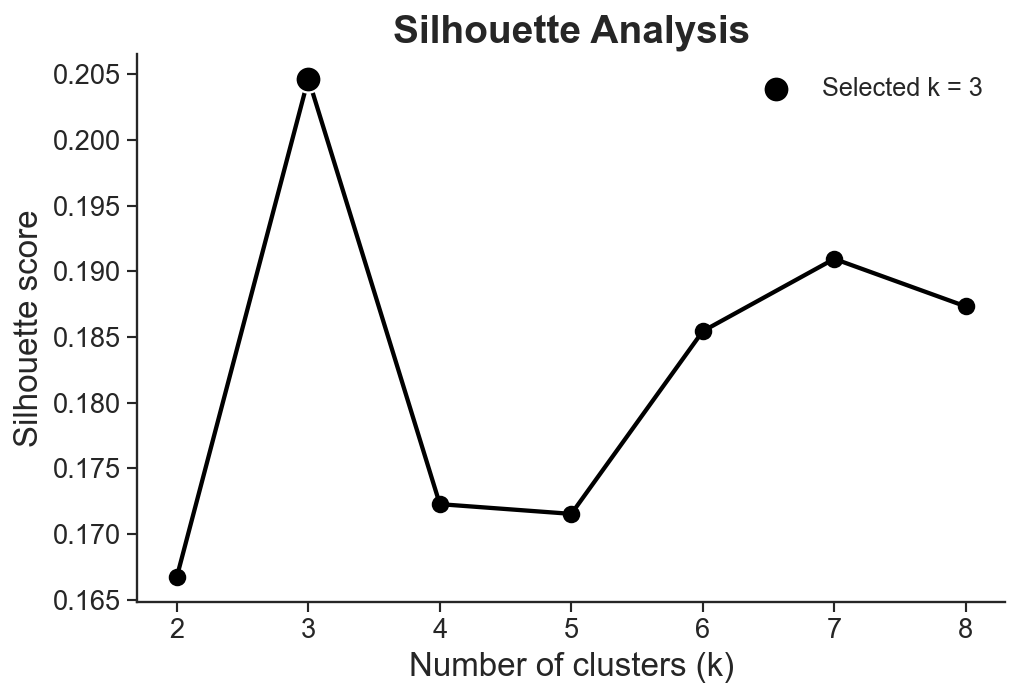

Saved: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis/Kmeans_silhouette_selection.png


In [24]:
# ============================================================
# 9. Silhouette plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.2)
)

ax.plot(
    silhouette_table["k"],
    silhouette_table["Silhouette score"],
    marker="o",
    markersize=8,
    linewidth=2.2,
    color='black',
)

best_row = silhouette_table.loc[
    silhouette_table["k"] == BEST_K
].iloc[0]

ax.scatter(
    [BEST_K],
    [best_row["Silhouette score"]],
    s=180,
    color='black',
    edgecolor="white",
    linewidth=1.2,
    zorder=5,
    label=f"Selected k = {BEST_K}",
)

ax.set_xticks(k_values)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Silhouette Analysis")
ax.legend(frameon=False)

clean_axes(ax)
plt.tight_layout()

silhouette_path = OUTPUT_DIR / "Kmeans_silhouette_selection.png"

plt.savefig(
    silhouette_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Saved: {silhouette_path}")

In [11]:
# ============================================================
# 10. Final K-means model
# ============================================================

kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=100,
)

raw_clusters = kmeans.fit_predict(
    X_cluster
)

# Re-label clusters deterministically from left to right by PC1 centroid.
cluster_centroids_full = np.vstack([
    X_pca[raw_clusters == cluster_id].mean(axis=0)
    for cluster_id in range(BEST_K)
])

cluster_order = np.argsort(
    cluster_centroids_full[:, 0]
)

cluster_remap = {
    old_cluster: new_cluster
    for new_cluster, old_cluster in enumerate(cluster_order)
}

clusters = np.array([
    cluster_remap[int(c)]
    for c in raw_clusters
])

pca_df["Cluster"] = clusters

cluster_palette = {
    cluster_id: CLUSTER_COLORS[
        cluster_id % len(CLUSTER_COLORS)
    ]
    for cluster_id in sorted(
        pca_df["Cluster"].unique()
    )
}

cluster_summary = (
    pca_df
    .groupby("Cluster", observed=True)
    .agg(
        Profiles=("PC1", "size"),
        PC1_centroid=("PC1", "mean"),
        PC2_centroid=("PC2", "mean"),
    )
    .reset_index()
)

display(cluster_summary)

,Cluster,Profiles,PC1_centroid,PC2_centroid
0,0,21,-7.077729,-2.363467
1,1,3,-5.251005,18.970063
2,2,24,6.849388,-0.303224


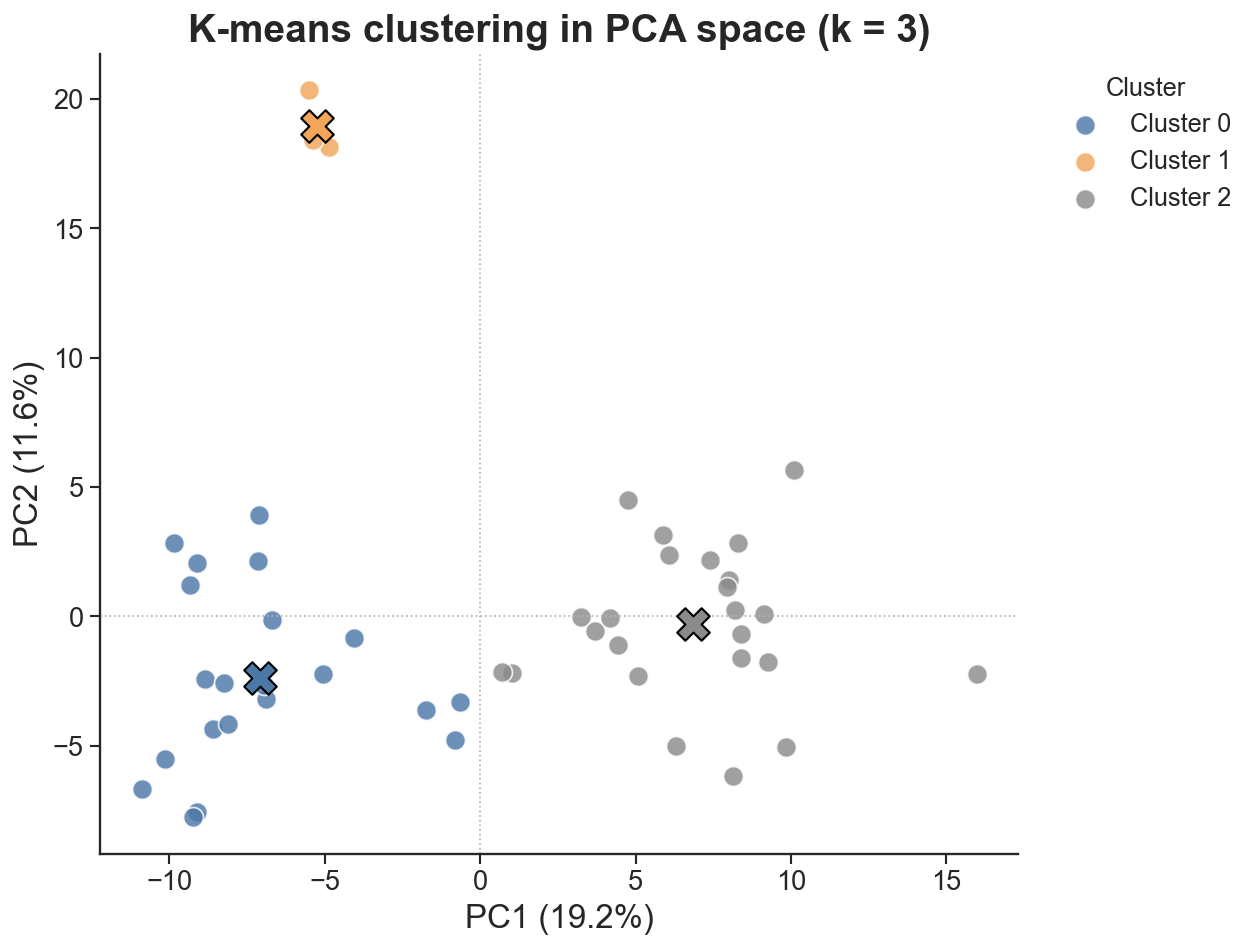

Saved: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis/PCA_Kmeans_clusters_publication.png


In [12]:
# ============================================================
# 11. K-means clusters in PCA space
# ============================================================

fig, ax = plt.subplots(
    figsize=(9.2, 7.0)
)

for cluster_id in sorted(
    pca_df["Cluster"].unique()
):
    subset = pca_df.loc[
        pca_df["Cluster"] == cluster_id
    ]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=105,
        alpha=0.82,
        color=cluster_palette[cluster_id],
        edgecolor="white",
        linewidth=0.9,
        label=f"Cluster {cluster_id}",
    )

# Cluster centroids.
for cluster_id in sorted(
    pca_df["Cluster"].unique()
):
    subset = pca_df.loc[
        pca_df["Cluster"] == cluster_id
    ]

    ax.scatter(
        subset["PC1"].mean(),
        subset["PC2"].mean(),
        s=280,
        marker="X",
        color=cluster_palette[cluster_id],
        edgecolor="black",
        linewidth=1.1,
        zorder=6,
    )

ax.axhline(
    0,
    color="#B5B5B5",
    linewidth=0.9,
    linestyle=":",
)

ax.axvline(
    0,
    color="#B5B5B5",
    linewidth=0.9,
    linestyle=":",
)

ax.set_xlabel(
    f"PC1 ({explained_variance[0]:.1f}%)"
)

ax.set_ylabel(
    f"PC2 ({explained_variance[1]:.1f}%)"
)

ax.set_title(
    f"K-means clustering in PCA space (k = {BEST_K})"
)

ax.legend(
    title="Cluster",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

clean_axes(ax)
plt.tight_layout()

cluster_path = OUTPUT_DIR / "PCA_Kmeans_clusters_publication.png"

plt.savefig(
    cluster_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Saved: {cluster_path}")

## 7. Bubble plot

The bubble plot shows how the replicate profiles of each biological condition are distributed among the K-means clusters. Bubble size corresponds to the number of profiles assigned to that condition–cluster combination. Bubble colour corresponds to the **biological condition**, preserving G0-arrested = green and Proliferative = purple.

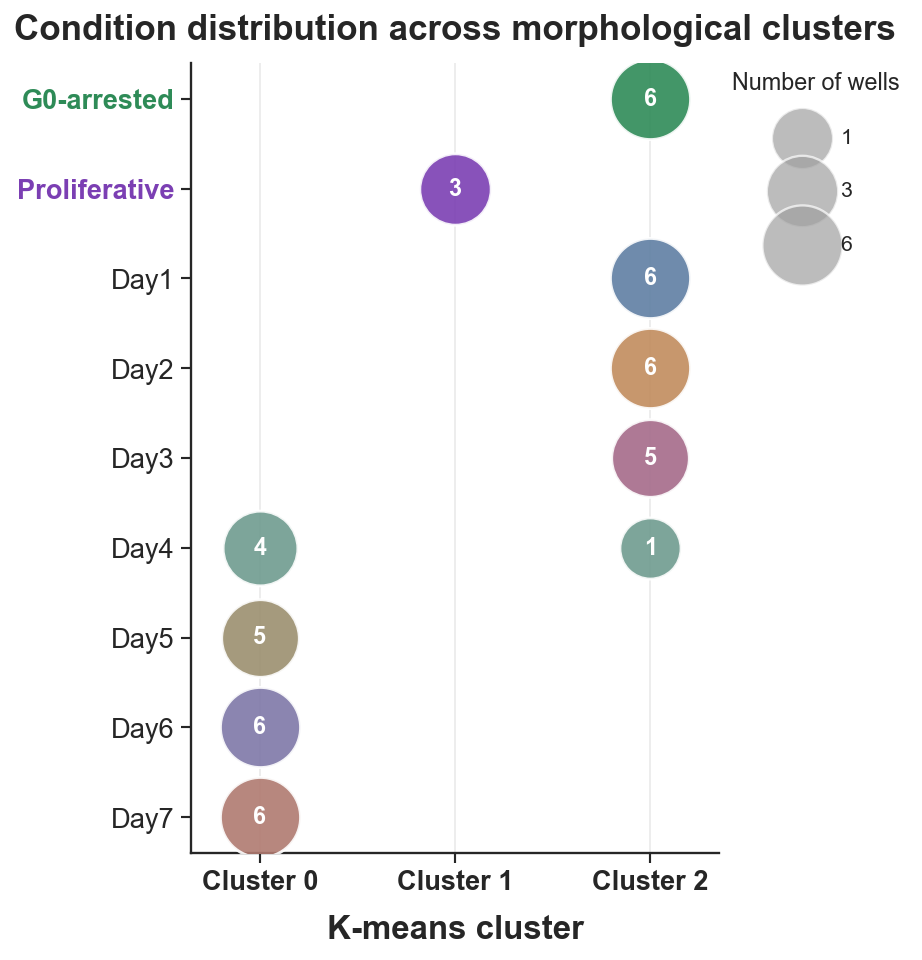

Saved: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis/Kmeans_condition_bubble_plot_publication_compact.png


,Metadata_condition,Cluster,Count
0,G0-arrested,0,0
1,G0-arrested,1,0
2,G0-arrested,2,6
3,Proliferative,0,0
4,Proliferative,1,3
5,Proliferative,2,0
6,Day1,0,0
7,Day1,1,0
8,Day1,2,6
9,Day2,0,0


In [26]:
# ============================================================
# 12. Bubble plot: condition × K-means cluster
# Compact publication version
# ============================================================

bubble_df = (
    pca_df
    .groupby(
        [CONDITION_COL, "Cluster"],
        observed=True,
    )
    .size()
    .reset_index(name="Count")
)

# ------------------------------------------------------------
# Ensure all condition × cluster combinations are represented
# ------------------------------------------------------------
cluster_ids = sorted(
    pca_df["Cluster"].unique()
)

all_combinations = pd.MultiIndex.from_product(
    [
        condition_order,
        cluster_ids,
    ],
    names=[
        CONDITION_COL,
        "Cluster",
    ],
)

bubble_df = (
    bubble_df
    .set_index(
        [CONDITION_COL, "Cluster"]
    )
    .reindex(
        all_combinations,
        fill_value=0,
    )
    .reset_index()
)

# ------------------------------------------------------------
# Y-axis order
# ------------------------------------------------------------
condition_to_y = {
    condition: i
    for i, condition in enumerate(
        condition_order[::-1]
    )
}

# ------------------------------------------------------------
# Compact X-axis positions
# ------------------------------------------------------------
# Slightly compress the horizontal distance between clusters.
cluster_positions = {
    cluster_id: i * 0.82
    for i, cluster_id in enumerate(
        cluster_ids
    )
}

# ------------------------------------------------------------
# Figure size
# ------------------------------------------------------------
fig_height = max(
    6.2,
    0.52 * len(condition_order) + 2.4,
)

fig, ax = plt.subplots(
    figsize=(6.8, fig_height)
)

# ------------------------------------------------------------
# Bubble size
# ------------------------------------------------------------
max_count = max(
    1,
    bubble_df["Count"].max(),
)

MIN_BUBBLE_SIZE = 500
MAX_BUBBLE_SIZE = 1700

# ------------------------------------------------------------
# Draw bubbles
# ------------------------------------------------------------
for _, row in bubble_df.iterrows():

    count = int(
        row["Count"]
    )

    if count <= 0:
        continue

    condition = str(
        row[CONDITION_COL]
    )

    cluster_id = int(
        row["Cluster"]
    )

    bubble_size = (
        MIN_BUBBLE_SIZE
        + (
            MAX_BUBBLE_SIZE
            - MIN_BUBBLE_SIZE
        )
        * np.sqrt(
            count / max_count
        )
    )

    ax.scatter(
        cluster_positions[
            cluster_id
        ],
        condition_to_y[
            condition
        ],
        s=bubble_size,
        color=condition_palette[
            condition
        ],
        alpha=0.90,
        edgecolor="white",
        linewidth=1.5,
        zorder=3,
    )

    # Count inside each bubble
    ax.text(
        cluster_positions[
            cluster_id
        ],
        condition_to_y[
            condition
        ],
        f"{count:,}",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white",
        zorder=4,
    )

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------
ax.set_xticks(
    list(
        cluster_positions.values()
    )
)

ax.set_xticklabels(
    [
        f"Cluster {cluster_id}"
        for cluster_id in cluster_ids
    ],
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel(
    "K-means cluster",
    fontsize=17,
    fontweight="bold",
    labelpad=10,
)

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------
ax.set_yticks(
    list(
        condition_to_y.values()
    )
)

ax.set_yticklabels(
    list(
        condition_to_y.keys()
    ),
    fontsize=13,
)

ax.set_ylabel("")

# Highlight reference states
for tick in ax.get_yticklabels():

    label = tick.get_text()

    if label == "G0-arrested":

        tick.set_color(
            G0_COLOR
        )

        tick.set_fontweight(
            "bold"
        )

    elif label == "Proliferative":

        tick.set_color(
            PROLIF_COLOR
        )

        tick.set_fontweight(
            "bold"
        )

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------
ax.set_title(
    "Condition distribution across morphological clusters",
    fontsize=18,
    fontweight="bold",
    pad=12,
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------
ax.grid(
    axis="x",
    color="#E8E8E8",
    linewidth=0.8,
    zorder=0,
)

ax.set_axisbelow(True)

# Give a little margin around the first/last cluster
if len(cluster_positions) > 1:

    x_values = list(
        cluster_positions.values()
    )

    spacing = (
        x_values[1]
        - x_values[0]
    )

    ax.set_xlim(
        min(x_values) - spacing * 0.35,
        max(x_values) + spacing * 0.35,
    )

else:

    only_x = list(
        cluster_positions.values()
    )[0]

    ax.set_xlim(
        only_x - 0.5,
        only_x + 0.5,
    )

clean_axes(ax)

# ------------------------------------------------------------
# Bubble-size legend
# ------------------------------------------------------------
legend_counts = sorted(
    {
        1,
        max(
            1,
            int(
                round(
                    max_count / 2
                )
            ),
        ),
        int(
            max_count
        ),
    }
)

size_handles = []

for count in legend_counts:

    legend_size = (
        MIN_BUBBLE_SIZE
        + (
            MAX_BUBBLE_SIZE
            - MIN_BUBBLE_SIZE
        )
        * np.sqrt(
            count / max_count
        )
    )

    handle = ax.scatter(
        [],
        [],
        s=legend_size,
        color="#A0A0A0",
        alpha=0.70,
        edgecolor="white",
        linewidth=1.2,
        label=f"{count:,}",
    )

    size_handles.append(
        handle
    )

ax.legend(
    handles=size_handles,
    title="Number of wells",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
    fontsize=11,
    title_fontsize=12,
    labelspacing=1.6,
    borderaxespad=0,
)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------
plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
bubble_path = (
    OUTPUT_DIR
    / "Kmeans_condition_bubble_plot_publication_compact.png"
)

plt.savefig(
    bubble_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(
    f"Saved: {bubble_path}"
)

display(
    bubble_df
)

## 8. PCA loadings

This optional panel summarizes the features contributing most strongly to PC1 and PC2. PCA loadings describe contributions to global variance and should not be interpreted as supervised feature importance.

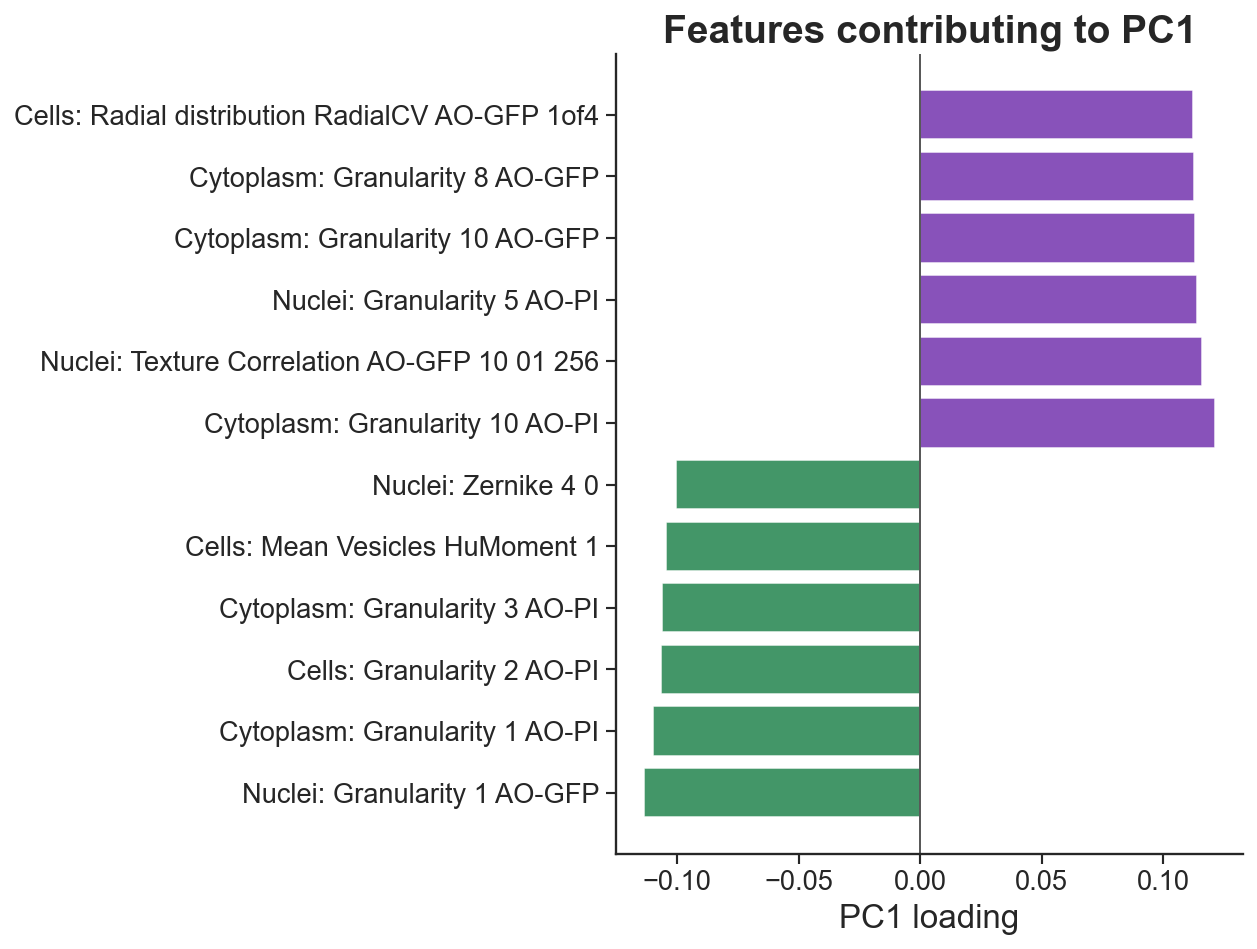

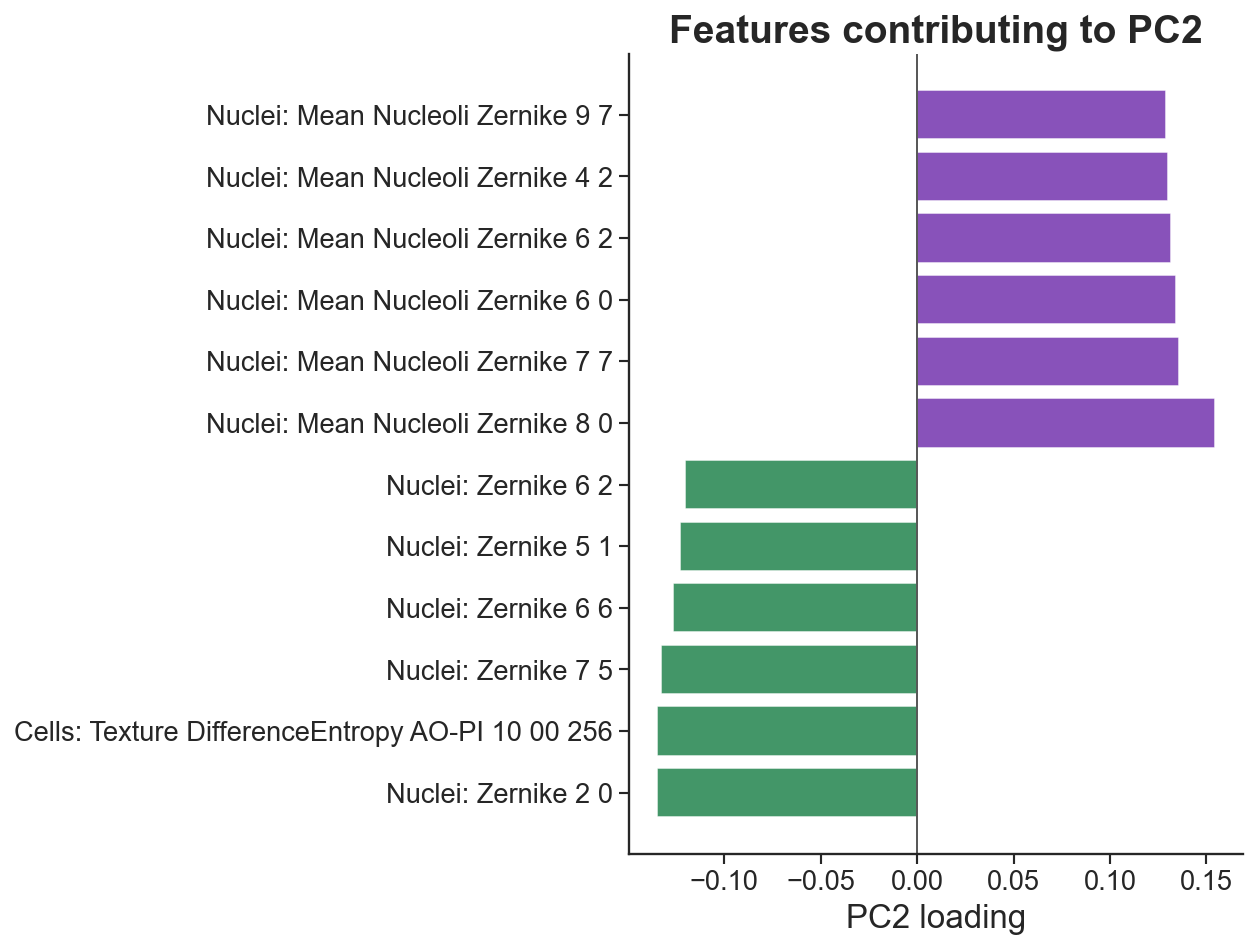

In [14]:
# ============================================================
# 13. Top PCA loadings for PC1 and PC2
# ============================================================

def shorten_feature_name(
    name,
    max_len=50,
):
    replacements = {
        "Nuclei_": "Nuclei: ",
        "Cells_": "Cells: ",
        "Cytoplasm_": "Cytoplasm: ",
        "AreaShape_": "",
        "Intensity_": "Intensity ",
        "Texture_": "Texture ",
        "Granularity_": "Granularity ",
        "RadialDistribution_": "Radial distribution ",
        "AOGFP": "AO-GFP",
        "AOPI": "AO-PI",
    }

    out = str(name)

    for old, new in replacements.items():
        out = out.replace(
            old,
            new,
        )

    out = out.replace(
        "__",
        "_",
    ).replace(
        "_",
        " ",
    )

    out = re.sub(
        r"\s+",
        " ",
        out,
    ).strip()

    if len(out) > max_len:
        out = (
            out[: max_len - 3].rstrip()
            + "..."
        )

    return out


def plot_pca_loadings(
    pc_index,
    top_n=6,
):
    loadings = pd.Series(
        pca.components_[pc_index],
        index=feature_cols,
    )

    negative = loadings.nsmallest(
        top_n
    )

    positive = loadings.nlargest(
        top_n
    )

    selected = pd.concat([
        negative,
        positive,
    ])

    colors = [
        G0_COLOR if value < 0
        else PROLIF_COLOR
        for value in selected.values
    ]

    labels = [
        shorten_feature_name(x)
        for x in selected.index
    ]

    fig, ax = plt.subplots(
        figsize=(9.2, 7.0)
    )

    y_positions = np.arange(
        len(selected)
    )

    ax.barh(
        y_positions,
        selected.values,
        color=colors,
        alpha=0.90,
        edgecolor="white",
        linewidth=0.8,
    )

    ax.axvline(
        0,
        color="#555555",
        linewidth=1.0,
    )

    ax.set_yticks(
        y_positions
    )

    ax.set_yticklabels(
        labels,
        fontsize=12,
    )

    pc_name = f"PC{pc_index + 1}"

    ax.set_xlabel(
        f"{pc_name} loading"
    )

    ax.set_ylabel("")

    ax.set_title(
        f"Features contributing to {pc_name}"
    )

    clean_axes(ax)
    plt.tight_layout()

    path = OUTPUT_DIR / (
        f"{pc_name}_top_loadings_publication.png"
    )

    plt.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    table = pd.DataFrame({
        "Feature": selected.index,
        "Loading": selected.values,
    })

    table.to_csv(
        OUTPUT_DIR / (
            f"{pc_name}_top_loadings.csv"
        ),
        index=False,
    )

    return table


pc1_loadings = plot_pca_loadings(
    0,
    top_n=6,
)

pc2_loadings = plot_pca_loadings(
    1,
    top_n=6,
)

## 9. Export analysis tables

In [15]:
# ============================================================
# 14. Export reproducible analysis tables
# ============================================================

export_df = analysis_df.copy()

export_df["PC1"] = X_pca[:, 0]
export_df["PC2"] = X_pca[:, 1]
export_df["Kmeans_Cluster"] = clusters

export_df.to_csv(
    OUTPUT_DIR / "PCA_Kmeans_profile_assignments.csv",
    index=False,
)

silhouette_table.to_csv(
    OUTPUT_DIR / "Kmeans_silhouette_scores.csv",
    index=False,
)

cluster_summary.to_csv(
    OUTPUT_DIR / "Kmeans_cluster_summary.csv",
    index=False,
)

bubble_df.to_csv(
    OUTPUT_DIR / "Kmeans_condition_bubble_table.csv",
    index=False,
)

pca_variance_table = pd.DataFrame({
    "Principal component": np.arange(
        1,
        len(explained_variance) + 1,
    ),
    "Explained variance (%)": explained_variance,
    "Cumulative variance (%)": cumulative_variance,
})

pca_variance_table.to_csv(
    OUTPUT_DIR / "PCA_explained_variance.csv",
    index=False,
)

print("Export complete.")
print(f"Files saved in: {OUTPUT_DIR.resolve()}")

Export complete.
Files saved in: /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Dormancy_Recovery/Analysis


## Interpretation guide

- **PCA** is unsupervised and displays the dominant sources of variance across all morphological profiles.
- **K-means** is also unsupervised and groups profiles according to their proximity in the retained PCA space.
- The **bubble plot** does not redefine the biological conditions. It summarizes how replicate profiles from each condition distribute across the K-means clusters.
- G0-arrested is always green and Proliferative is always purple. Other treatments use a muted complementary palette.